# Part A

## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## A.2 Recover Homographies

In [4]:
def computeH(im1_pts, im2_pts):
    # im1_pts is P, im2_pts is P'

    A = []
    b = []
    
    for (x, y), (xp, yp) in zip(im1_pts, im2_pts):
        # Row 1
        A.append([x, y, 1, 0, 0, 0, -x*xp, -y*xp])
        b.append(xp)
        
        # Row 2
        A.append([0, 0, 0, x, y, 1, -x*yp, -y*yp])
        b.append(yp)

    A = np.array(A)
    b = np.array(b)

    h, _, _, _ = np.linalg.lstsq(A, b)
    
    H = np.append(h, 1).reshape(3, 3)
    return H

Recovered homography matrix:
[[ 1.31117594e+00 -1.95757437e-02 -2.82431476e+02]
 [ 2.39968172e-01  1.18320334e+00 -1.05834355e+02]
 [ 4.17352114e-04 -4.36276187e-06  1.00000000e+00]]


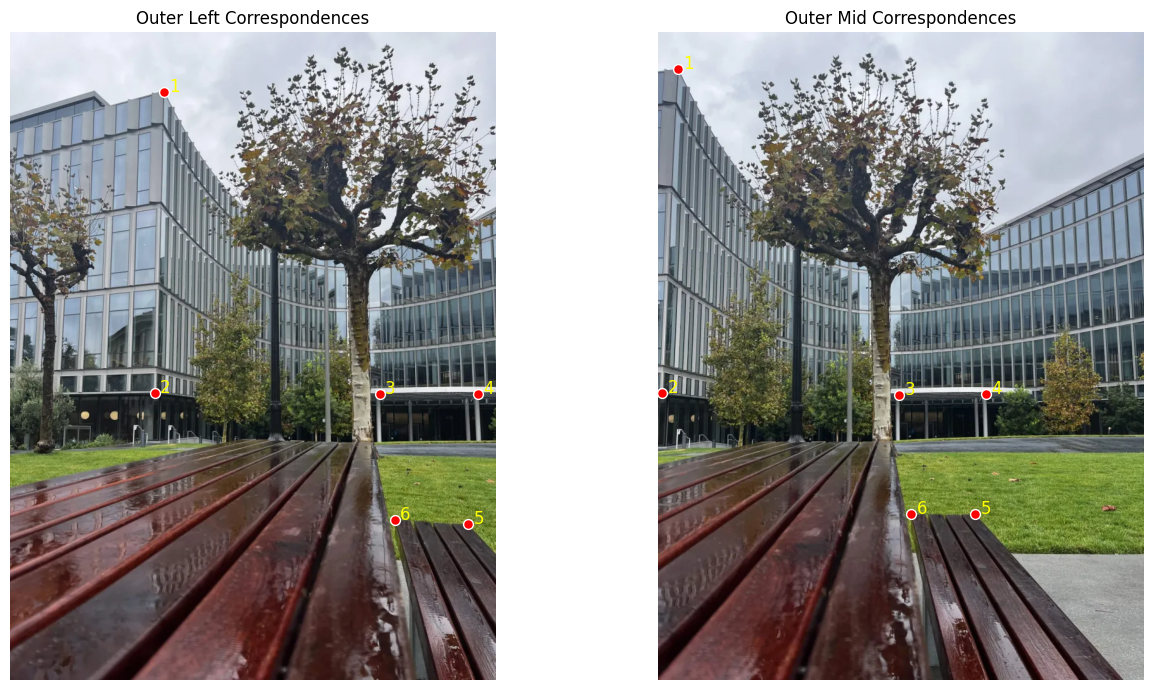

In [ ]:
im_outer_left = plt.imread('data/outer_left.jpg')
im_outer_mid = plt.imread('data/outer_mid.jpg')
outer_left_pts = np.array([[243,94],[229,569],[584,571],[740,571],[724,777],[608,771]])
outer_mid_pts = np.array([[31,58],[6,569],[381,573],[518,571],[501,761],[400,761]])

H = computeH(outer_left_pts, outer_mid_pts)

print("Recovered homography matrix:")
print(H)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

plot_data = [
    (im_outer_left, outer_left_pts, "Outer Left Correspondences"),
    (im_outer_mid, outer_mid_pts, "Outer Mid Correspondences")
]

for ax, (img, pts, title) in zip(axes, plot_data):
    ax.imshow(img)
    ax.scatter(pts[:, 0], pts[:, 1], c='red', s=50, edgecolors='white')
    
    for i, (x, y) in enumerate(pts):
        ax.text(x + 8, y, str(i + 1), color='yellow', fontsize=12)
        
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

## A.3 Warp the Images

In [3]:
def warpImageNearestNeighbor(im, H, bounds=None):
    h, w = im.shape[:2]
    
    if bounds is None:
        corners = np.array([[0, 0, 1], [w, 0, 1], [0, h, 1], [w, h, 1]]).T
        warped = H @ corners
        warped = warped[:2, :] / warped[2, :] #normalize
        
        min_x, max_x = int(np.floor(np.min(warped[0]))), int(np.ceil(np.max(warped[0])))
        min_y, max_y = int(np.floor(np.min(warped[1]))), int(np.ceil(np.max(warped[1])))
    else:
        min_x, min_y, max_x, max_y = (int(b) for b in bounds)
    out_w = max_x - min_x
    out_h = max_y - min_y
    out_im = np.zeros((out_h, out_w, 4), dtype=im.dtype)
    
    H_inv = np.linalg.inv(H)
    
    y_out, x_out = np.indices((out_h, out_w))
    x_global = x_out + min_x
    y_global = y_out + min_y
    p_out = np.stack([x_global, y_global, np.ones_like(x_global)], axis=-1)
 
    p_src = p_out @ H_inv.T
    x_src = p_src[..., 0] / p_src[..., 2]
    y_src = p_src[..., 1] / p_src[..., 2]
    x_nn = np.round(x_src).astype(int)
    y_nn = np.round(y_src).astype(int)
 
    valid = (0 <= x_nn) & (x_nn < w) & (0 <= y_nn) & (y_nn < h)
    out_im[valid, :3] = im[y_nn[valid], x_nn[valid], :3]
    out_im[valid, 3] = 255
 
    return out_im

def warpImageBilinear(im, H, bounds=None):
    h, w = im.shape[:2]
    
    if bounds is None:
        corners = np.array([[0, 0, 1], [w, 0, 1], [0, h, 1], [w, h, 1]]).T
        warped = H @ corners
        warped = warped[:2, :] / warped[2, :] #normalize
        
        min_x, max_x = int(np.floor(np.min(warped[0]))), int(np.ceil(np.max(warped[0])))
        min_y, max_y = int(np.floor(np.min(warped[1]))), int(np.ceil(np.max(warped[1])))
    else:
        min_x, min_y, max_x, max_y = (int(b) for b in bounds)
    out_w = max_x - min_x
    out_h = max_y - min_y
    out_im = np.zeros((out_h, out_w, 4), dtype=im.dtype)
    
    H_inv = np.linalg.inv(H)
    
    y_out, x_out = np.indices((out_h, out_w))
    x_global = x_out + min_x
    y_global = y_out + min_y
    p_out = np.stack([x_global, y_global, np.ones_like(x_global)], axis=-1)
 
    p_src = p_out @ H_inv.T
    x_src = p_src[..., 0] / p_src[..., 2]
    y_src = p_src[..., 1] / p_src[..., 2]
 
    x0 = np.floor(x_src).astype(int)
    y0 = np.floor(y_src).astype(int)
    x1 = x0 + 1
    y1 = y0 + 1
 
    valid = (0 <= x0) & (x1 < w) & (0 <= y0) & (y1 < h)
    x0, x1, y0, y1 = x0[valid], x1[valid], y0[valid], y1[valid]
    dx = (x_src[valid] - x0)[:, None]
    dy = (y_src[valid] - y0)[:, None]
 
    I00 = im[y0, x0, :3].astype(float)
    I10 = im[y0, x1, :3].astype(float)
    I01 = im[y1, x0, :3].astype(float)
    I11 = im[y1, x1, :3].astype(float)
 
    w00 = (1 - dx) * (1 - dy)
    w10 = dx * (1 - dy)
    w01 = (1 - dx) * dy
    w11 = dx * dy
 
    interpolated_rgb = (w00 * I00) + (w10 * I10) + (w01 * I01) + (w11 * I11)
 
    out_im[valid, :3] = np.clip(interpolated_rgb, 0, 255).astype(im.dtype)
    out_im[valid, 3] = 255
 
    return out_im

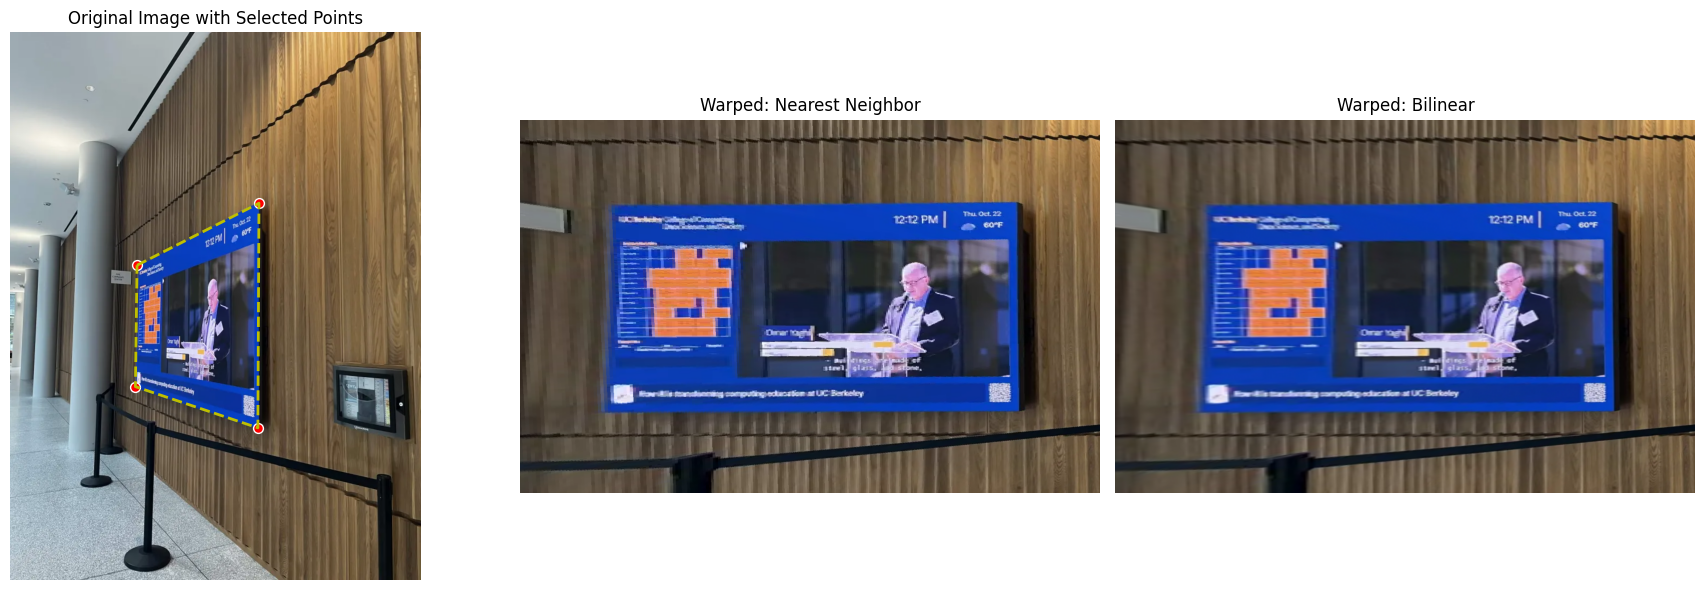

In [5]:
# rectification
im_board = plt.imread('data/board.jpg')
im_board_pts = np.array([
    [237, 435],
    [465, 319], 
    [463, 739],
    [234, 662]
])
im_board_flat_pts = np.array([
    [0, 0],
    [1000, 0],
    [1000, 500],
    [0, 500]
])

H = computeH(im_board_pts, im_board_flat_pts)

flat_bounds = (*im_board_flat_pts.min(axis=0)-200, *im_board_flat_pts.max(axis=0)+200)

warped_nn = warpImageNearestNeighbor(im_board, H, bounds=flat_bounds)
warped_bil = warpImageBilinear(im_board, H, bounds=flat_bounds)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(im_board)
axes[0].scatter(im_board_pts[:, 0], im_board_pts[:, 1], c='red', s=50, marker='o', edgecolors='white')

poly_pts = np.vstack([im_board_pts, im_board_pts[0]])
axes[0].plot(poly_pts[:, 0], poly_pts[:, 1], 'y--', linewidth=2)
axes[0].set_title("Original Image with Selected Points")
axes[0].axis('off')

axes[1].imshow(warped_nn)
axes[1].set_title("Warped: Nearest Neighbor")
axes[1].axis('off')

axes[2].imshow(warped_bil)
axes[2].set_title("Warped: Bilinear")
axes[2].axis('off')

plt.tight_layout()
plt.show()

# A.4 Blend the Images Into a Mosaic

In [6]:
from scipy.ndimage import gaussian_filter

def create_alpha_mask(h, w):
    y_idx, x_idx = np.indices((h, w))
    
    y = (2.0 * y_idx / (h - 1)) - 1.0
    x = (2.0 * x_idx / (w - 1)) - 1.0
    
    dist = np.maximum(np.abs(x), np.abs(y))
    mask = 1.0 - dist
    
    return np.clip(mask, 0, 1)

def create_mosaic(images, homographies, sigma=8):
    # calculate the global output
    min_x, max_x = np.inf, -np.inf
    min_y, max_y = np.inf, -np.inf
    
    for im, H in zip(images, homographies):
        h, w = im.shape[:2]
        corners = np.array([[0, 0, 1], [w, 0, 1], [0, h, 1], [w, h, 1]]).T
        warped = H @ corners
        warped = warped[:2, :] / warped[2, :]
        min_x = min(min_x, np.min(warped[0]))
        max_x = max(max_x, np.max(warped[0]))
        min_y = min(min_y, np.min(warped[1]))
        max_y = max(max_y, np.max(warped[1]))
        
    min_x, max_x = int(np.floor(min_x)), int(np.ceil(max_x))
    min_y, max_y = int(np.floor(min_y)), int(np.ceil(max_y))
    bounds = (min_x, min_y, max_x, max_y)
    
    # warp each image
    warped_rgbs, warped_weights = [], []
    for im, H in zip(images, homographies):
        h, w = im.shape[:2]
        
        warped_rgbs.append(warpImageBilinear(im, H, bounds=bounds)[:, :, :3].astype(float))
        
        alpha = create_alpha_mask(h, w)
        alpha_3ch = np.stack([alpha, alpha, alpha], axis=-1)
        warped = warpImageBilinear(alpha_3ch, H, bounds=bounds)
        warped_weights.append(warped[:, :, 0])
        
    # split each image into low/high frequencies
    lows, highs = [], []
    for rgb, wt in zip(warped_rgbs, warped_weights):
        mask = (wt > 0).astype(float)[..., None]
        blurred_mask = gaussian_filter(mask, (sigma, sigma, 0))
        low = gaussian_filter(rgb * mask, (sigma, sigma, 0)) / np.maximum(blurred_mask, 1e-8)
        high = (rgb - low) * mask
        lows.append(low)
        highs.append(high)
        
    # blend
    w_stack = np.stack(warped_weights, axis=0)
    low_stack = np.stack(lows, axis=0)

    total_weight = np.maximum(np.sum(w_stack, axis=0), 1e-8)[..., None]
    low_blend = np.sum(low_stack * w_stack[..., None], axis=0) / total_weight

    winner = np.argmax(w_stack, axis=0)
    high_pick = np.choose(winner[..., None], highs)

    return np.clip(low_blend + high_pick, 0, 255).astype(np.uint8)

In [7]:
def show_mosaic(images, names, mosaic, figsize=(14, 14)):
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, len(images), height_ratios=[1, 2])
    
    for i, (im, name) in enumerate(zip(images, names)):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(im)
        ax.set_title(name)
        ax.axis('off')
        
    ax = fig.add_subplot(gs[1, :])
    ax.imshow(mosaic)
    ax.set_title("Mosaic")
    ax.axis('off')
        
    plt.tight_layout()
    plt.show()

## Mosaic 1: Outer (left / mid / right, mid is the reference)

In [ ]:
im_outer_left = plt.imread('data/outer_left.jpg')
im_outer_mid = plt.imread('data/outer_mid.jpg')
im_outer_right = plt.imread('data/outer_right.jpg')

outer_left_pts = np.array([[372, 209], [339, 326], [343, 729], [538, 57], [523, 368], [511, 643], [661, 263], [610, 480], [593, 699]])
outer_mid_pts_l = np.array([[173, 197], [136, 316], [135, 738], [344, 69], [326, 372], [310, 642], [454, 282], [405, 484], [387, 694]])
outer_right_pts = np.array([[147, 247], [136, 386], [152, 710], [224, 255], [264, 593], [253, 780], [351, 294], [404, 502], [449, 728]])
outer_mid_pts_r = np.array([[408, 281], [404, 412], [434, 723], [480, 275], [538, 608], [537, 799], [612, 294], [686, 507], [755, 755]])

outer_images = [im_outer_left, im_outer_mid, im_outer_right]
outer_Hs = [computeH(outer_left_pts, outer_mid_pts_l), np.eye(3), computeH(outer_right_pts, outer_mid_pts_r)]

outer_mosaic = create_mosaic(outer_images, outer_Hs)
show_mosaic(outer_images, ["outer_left", "outer_mid (reference)", "outer_right"], outer_mosaic)

## Mosaic 2: Inner (left / mid / right, mid is the reference)

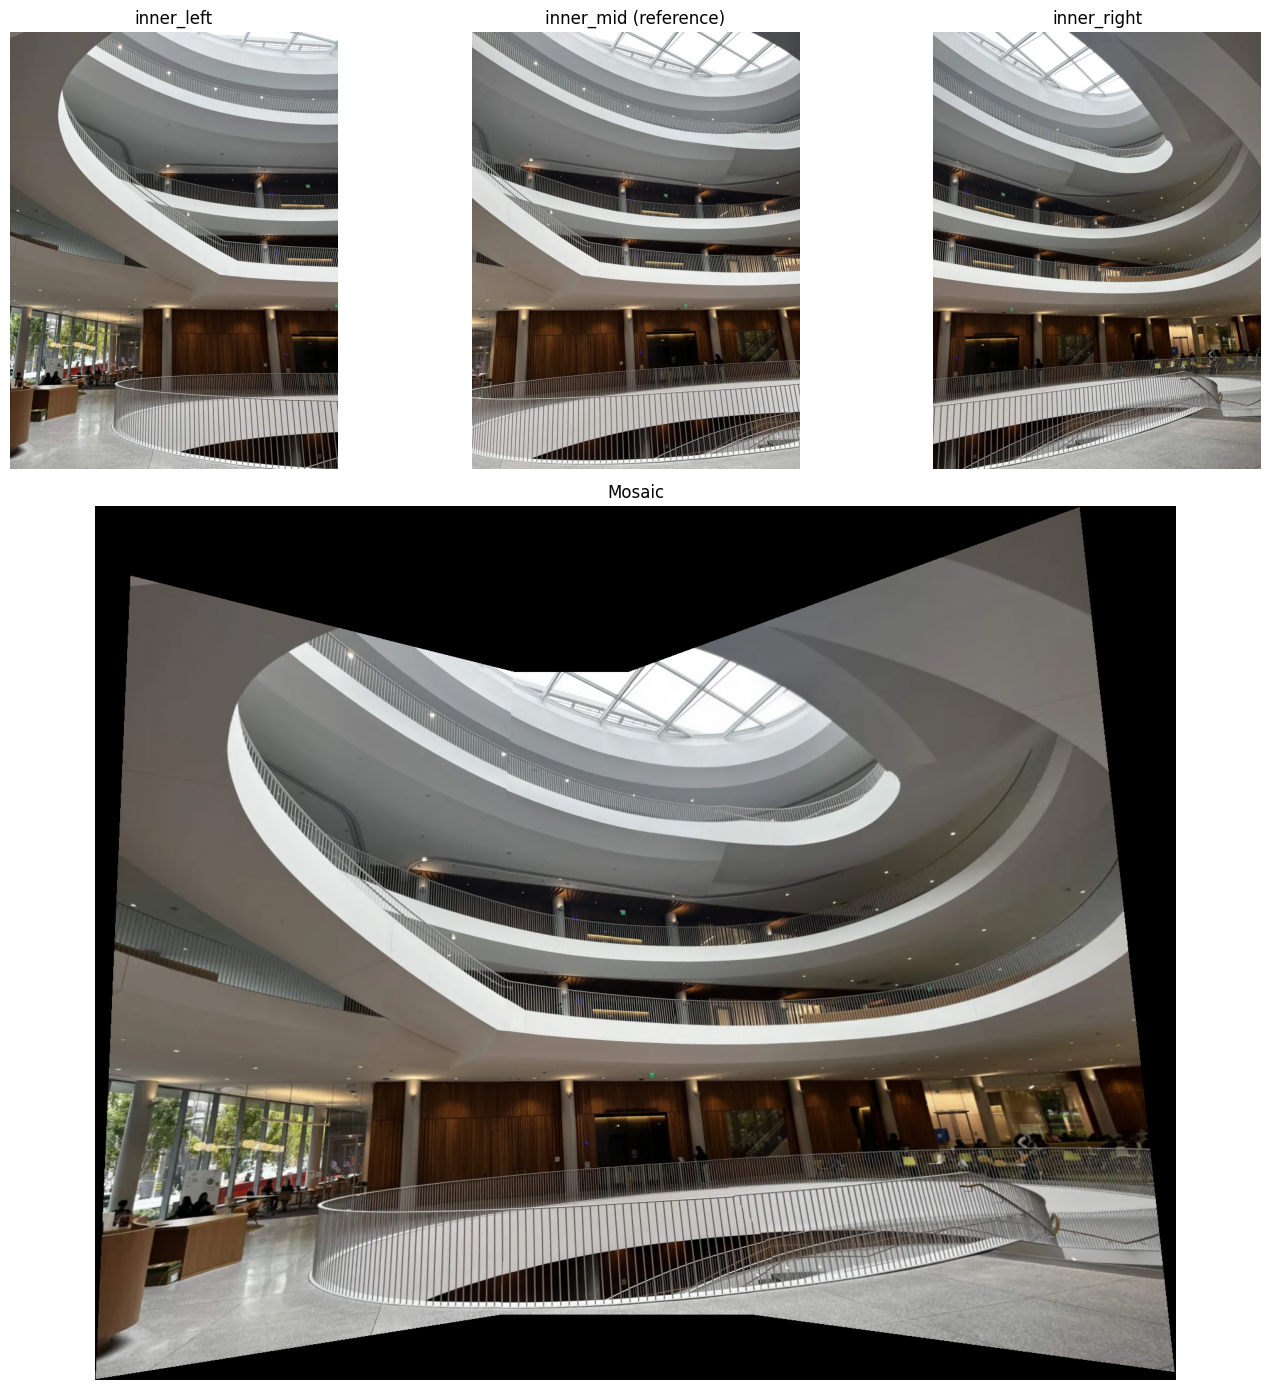

In [11]:
im_inner_left = plt.imread('data/inner_left.jpg')
im_inner_mid = plt.imread('data/inner_mid.jpg')
im_inner_right = plt.imread('data/inner_right.jpg')

inner_left_pts = np.array([[265, 335], [289, 358], [299, 727], [581, 335], [576, 486], [568, 854], [591, 340], [650, 531], [651, 792]])
inner_mid_pts_l = np.array([[16, 307], [43, 336], [38, 738], [352, 346], [341, 492], [318, 850], [361, 352], [407, 538], [397, 784]])
inner_right_pts = np.array([[80, 328], [53, 474], [139, 836], [234, 89], [262, 381], [248, 830], [369, 135], [390, 557], [385, 930]])
inner_mid_pts_r = np.array([[374, 347], [366, 485], [477, 821], [492, 81], [550, 366], [583, 820], [638, 85], [709, 532], [747, 935]])
assert len(inner_left_pts) >= 4 and len(inner_left_pts) == len(inner_mid_pts_l), "fill in the inner_left correspondences first"
assert len(inner_right_pts) >= 4 and len(inner_right_pts) == len(inner_mid_pts_r), "fill in the inner_right correspondences first"

inner_images = [im_inner_left, im_inner_mid, im_inner_right]
inner_Hs = [computeH(inner_left_pts, inner_mid_pts_l), np.eye(3), computeH(inner_right_pts, inner_mid_pts_r)]

inner_mosaic = create_mosaic(inner_images, inner_Hs)
show_mosaic(inner_images, ["inner_left", "inner_mid (reference)", "inner_right"], inner_mosaic)

## Mosaic 3: Gateway (bottom / middle / top, middle is the reference)

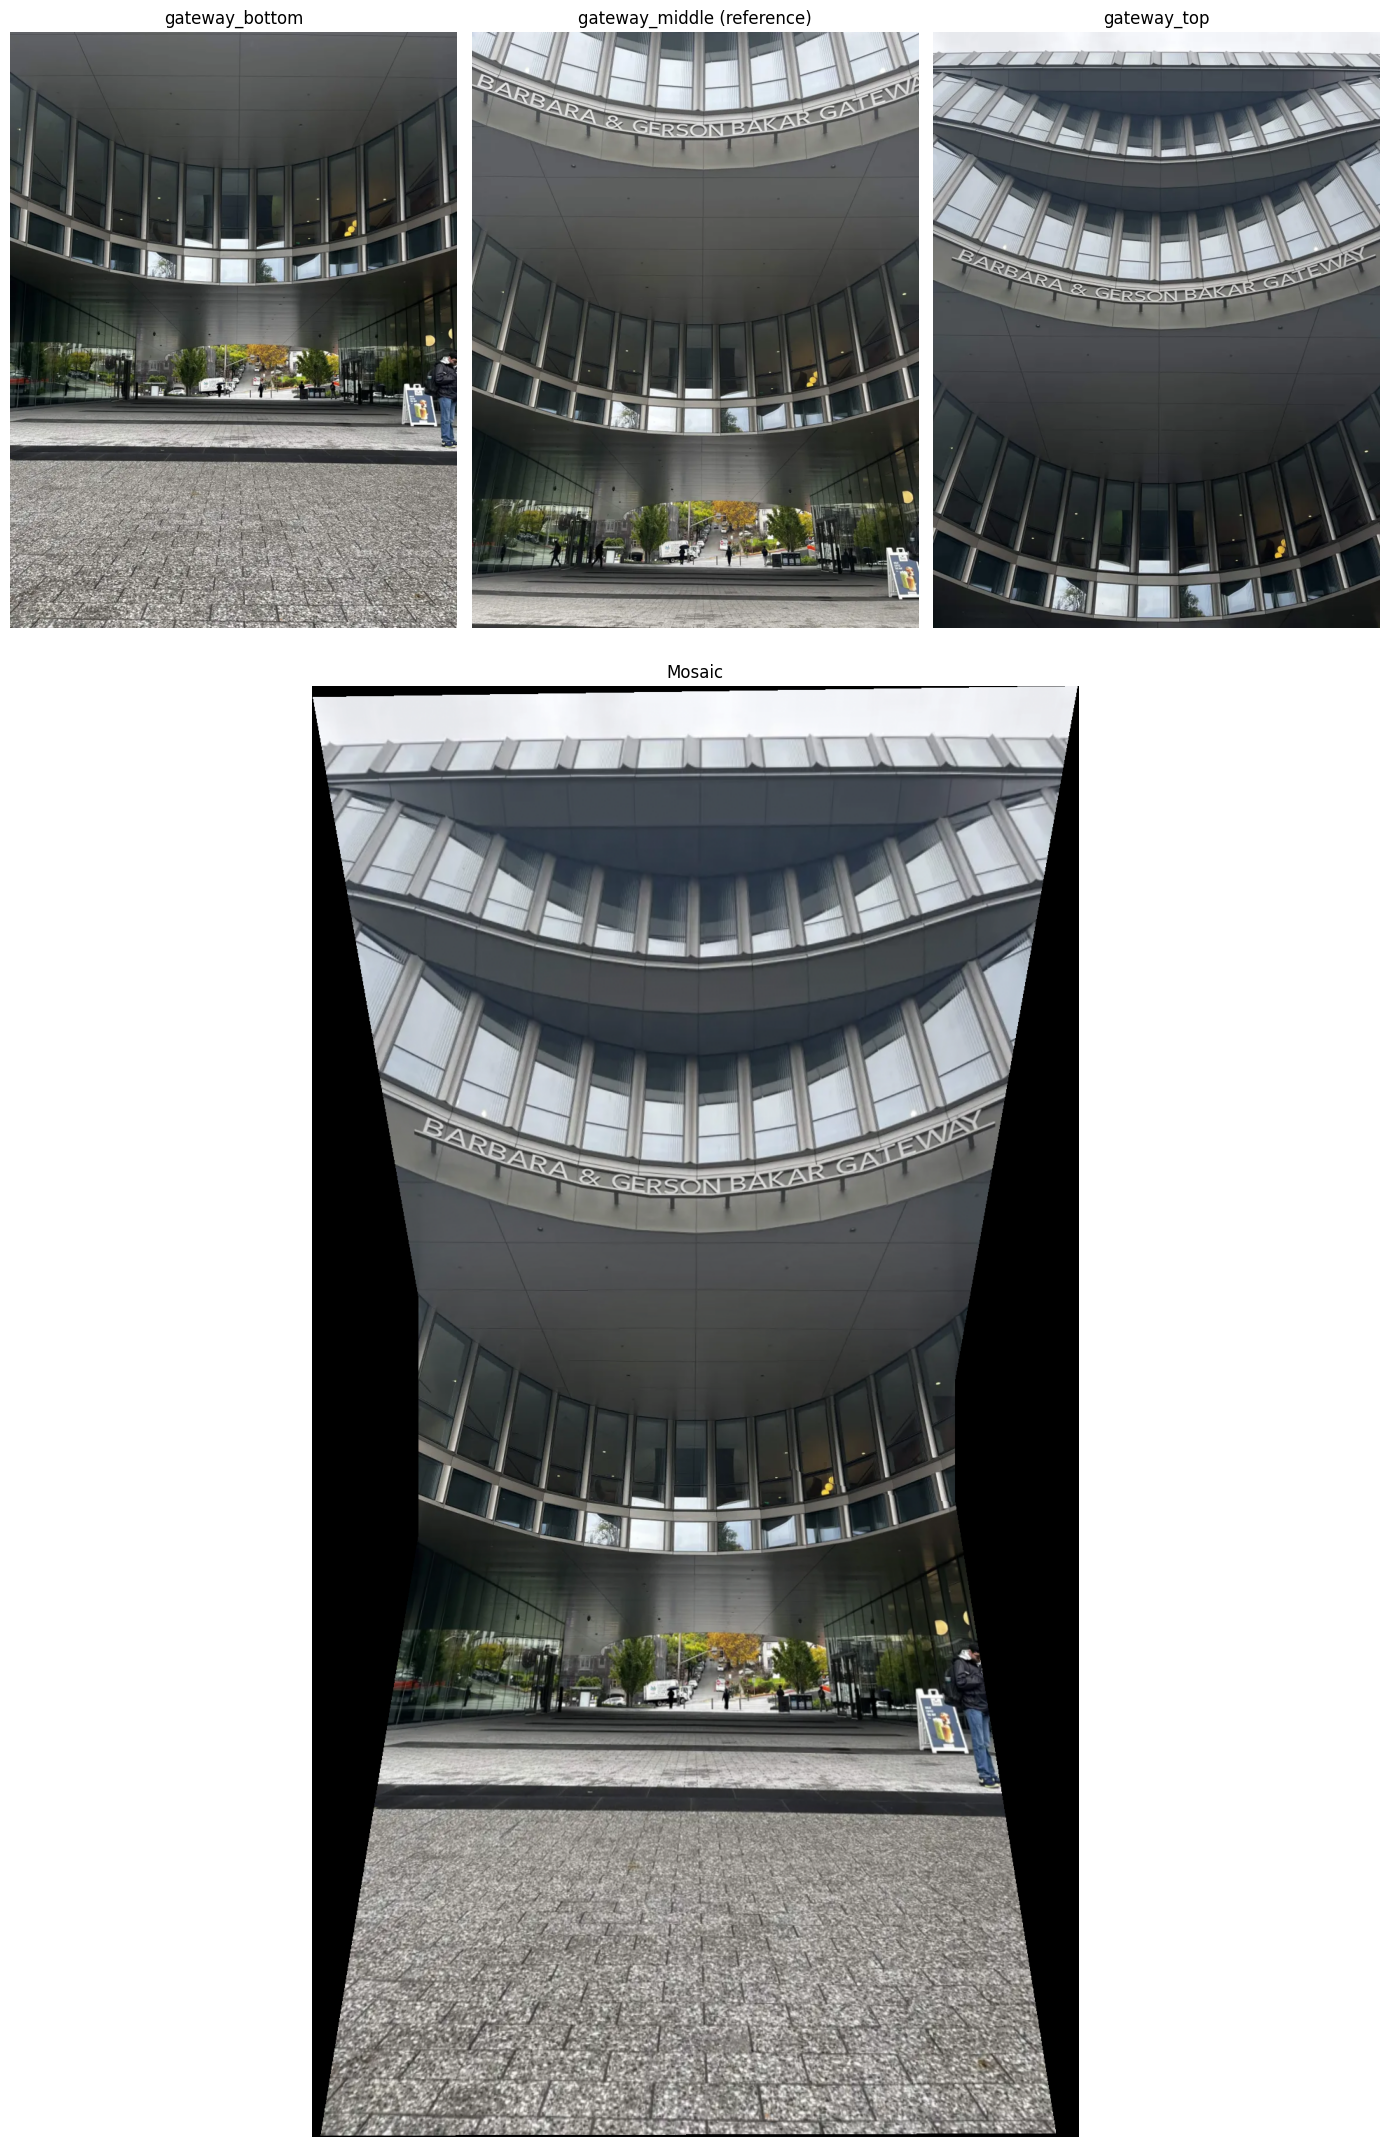

In [12]:
im_gateway_bottom = plt.imread('data/gateway_bottom.jpg')
im_gateway_middle = plt.imread('data/gateway_middle.jpg')
im_gateway_top = plt.imread('data/gateway_top.jpg')

gateway_bottom_pts = np.array([[234, 359], [155, 541], [93, 560], [297, 360], [406, 537], [403, 577], [541, 363], [632, 546], [539, 560]])
gateway_middle_pts_b = np.array([[240, 617], [143, 811], [74, 833], [303, 618], [412, 806], [409, 853], [544, 621], [654, 817], [556, 833]])
gateway_top_pts = np.array([[78, 398], [18, 773], [140, 950], [352, 449], [422, 1003], [650, 406], [597, 900]])
gateway_middle_pts_t = np.array([[48, 102], [48, 500], [179, 646], [358, 163], [425, 686], [693, 108], [585, 607]])
assert len(gateway_bottom_pts) >= 4 and len(gateway_bottom_pts) == len(gateway_middle_pts_b), "fill in the gateway_bottom correspondences first"
assert len(gateway_top_pts) >= 4 and len(gateway_top_pts) == len(gateway_middle_pts_t), "fill in the gateway_top correspondences first"

gateway_images = [im_gateway_bottom, im_gateway_middle, im_gateway_top]
gateway_Hs = [computeH(gateway_bottom_pts, gateway_middle_pts_b), np.eye(3), computeH(gateway_top_pts, gateway_middle_pts_t)]

gateway_mosaic = create_mosaic(gateway_images, gateway_Hs)
show_mosaic(gateway_images, ["gateway_bottom", "gateway_middle (reference)", "gateway_top"], gateway_mosaic, figsize=(14, 22))